Mask loaded: C:\Users\soyoo\URP_cdo_data\10~11\1115\common_spatial_mask.npy
Mask shape: (192, 288)
Valid grid cells: 11856

PR 45N: 6 members (e02, e03, e04, e05, e06, e07)

PR 30N: 6 members (e02, e03, e04, e05, e06, e07)

PR 15N: 6 members (e02, e03, e04, e05, e06, e07)

PR 0N: 6 members (e02, e03, e04, e05, e06, e07)

PR 15S: 6 members (e02, e03, e04, e05, e06, e07)

PR 30S: 6 members (e02, e03, e04, e05, e06, e07)

PR 45S: 6 members (e02, e03, e04, e05, e06, e07)


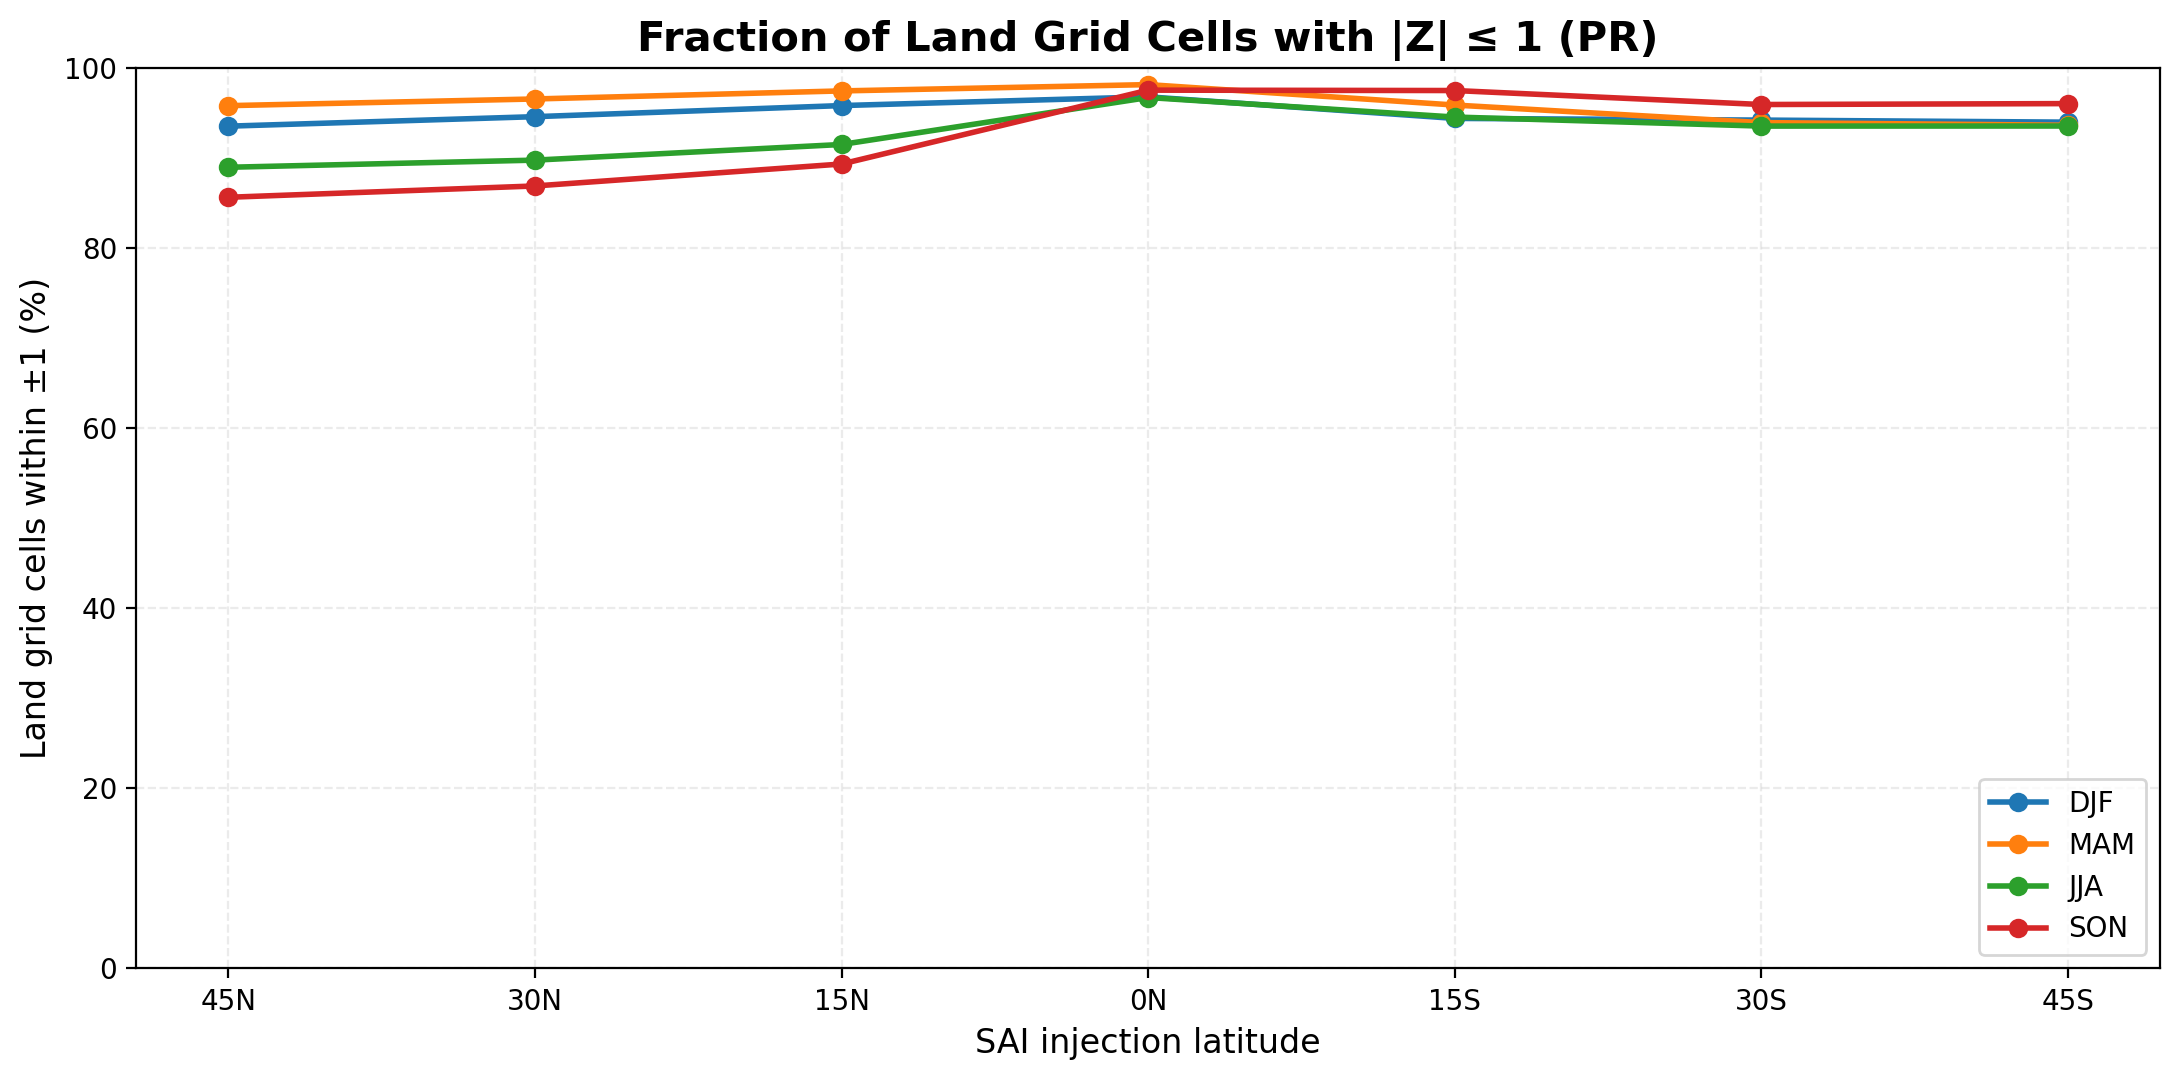

Saved: C:\Users\soyoo\URP_cdo_data\10~11\1118\PR_zscore_validation_within1_pooled.png

PR VALIDATION RESULTS

SAI 45N
  DJF: map |z|<=1:  93.5% | member |z|<=1:  91.7% | map |z|>3:   0.2%
  MAM: map |z|<=1:  95.8% | member |z|<=1:  94.9% | map |z|>3:   0.0%
  JJA: map |z|<=1:  88.9% | member |z|<=1:  88.3% | map |z|>3:   0.5%
  SON: map |z|<=1:  85.6% | member |z|<=1:  84.8% | map |z|>3:   0.3%

SAI 30N
  DJF: map |z|<=1:  94.6% | member |z|<=1:  92.7% | map |z|>3:   0.2%
  MAM: map |z|<=1:  96.5% | member |z|<=1:  95.9% | map |z|>3:   0.0%
  JJA: map |z|<=1:  89.7% | member |z|<=1:  89.2% | map |z|>3:   0.5%
  SON: map |z|<=1:  86.9% | member |z|<=1:  86.3% | map |z|>3:   0.3%

SAI 15N
  DJF: map |z|<=1:  95.8% | member |z|<=1:  95.0% | map |z|>3:   0.2%
  MAM: map |z|<=1:  97.4% | member |z|<=1:  97.1% | map |z|>3:   0.0%
  JJA: map |z|<=1:  91.5% | member |z|<=1:  91.2% | map |z|>3:   0.4%
  SON: map |z|<=1:  89.3% | member |z|<=1:  88.8% | map |z|>3:   0.3%

SAI 0N
  DJF: map |z|<=

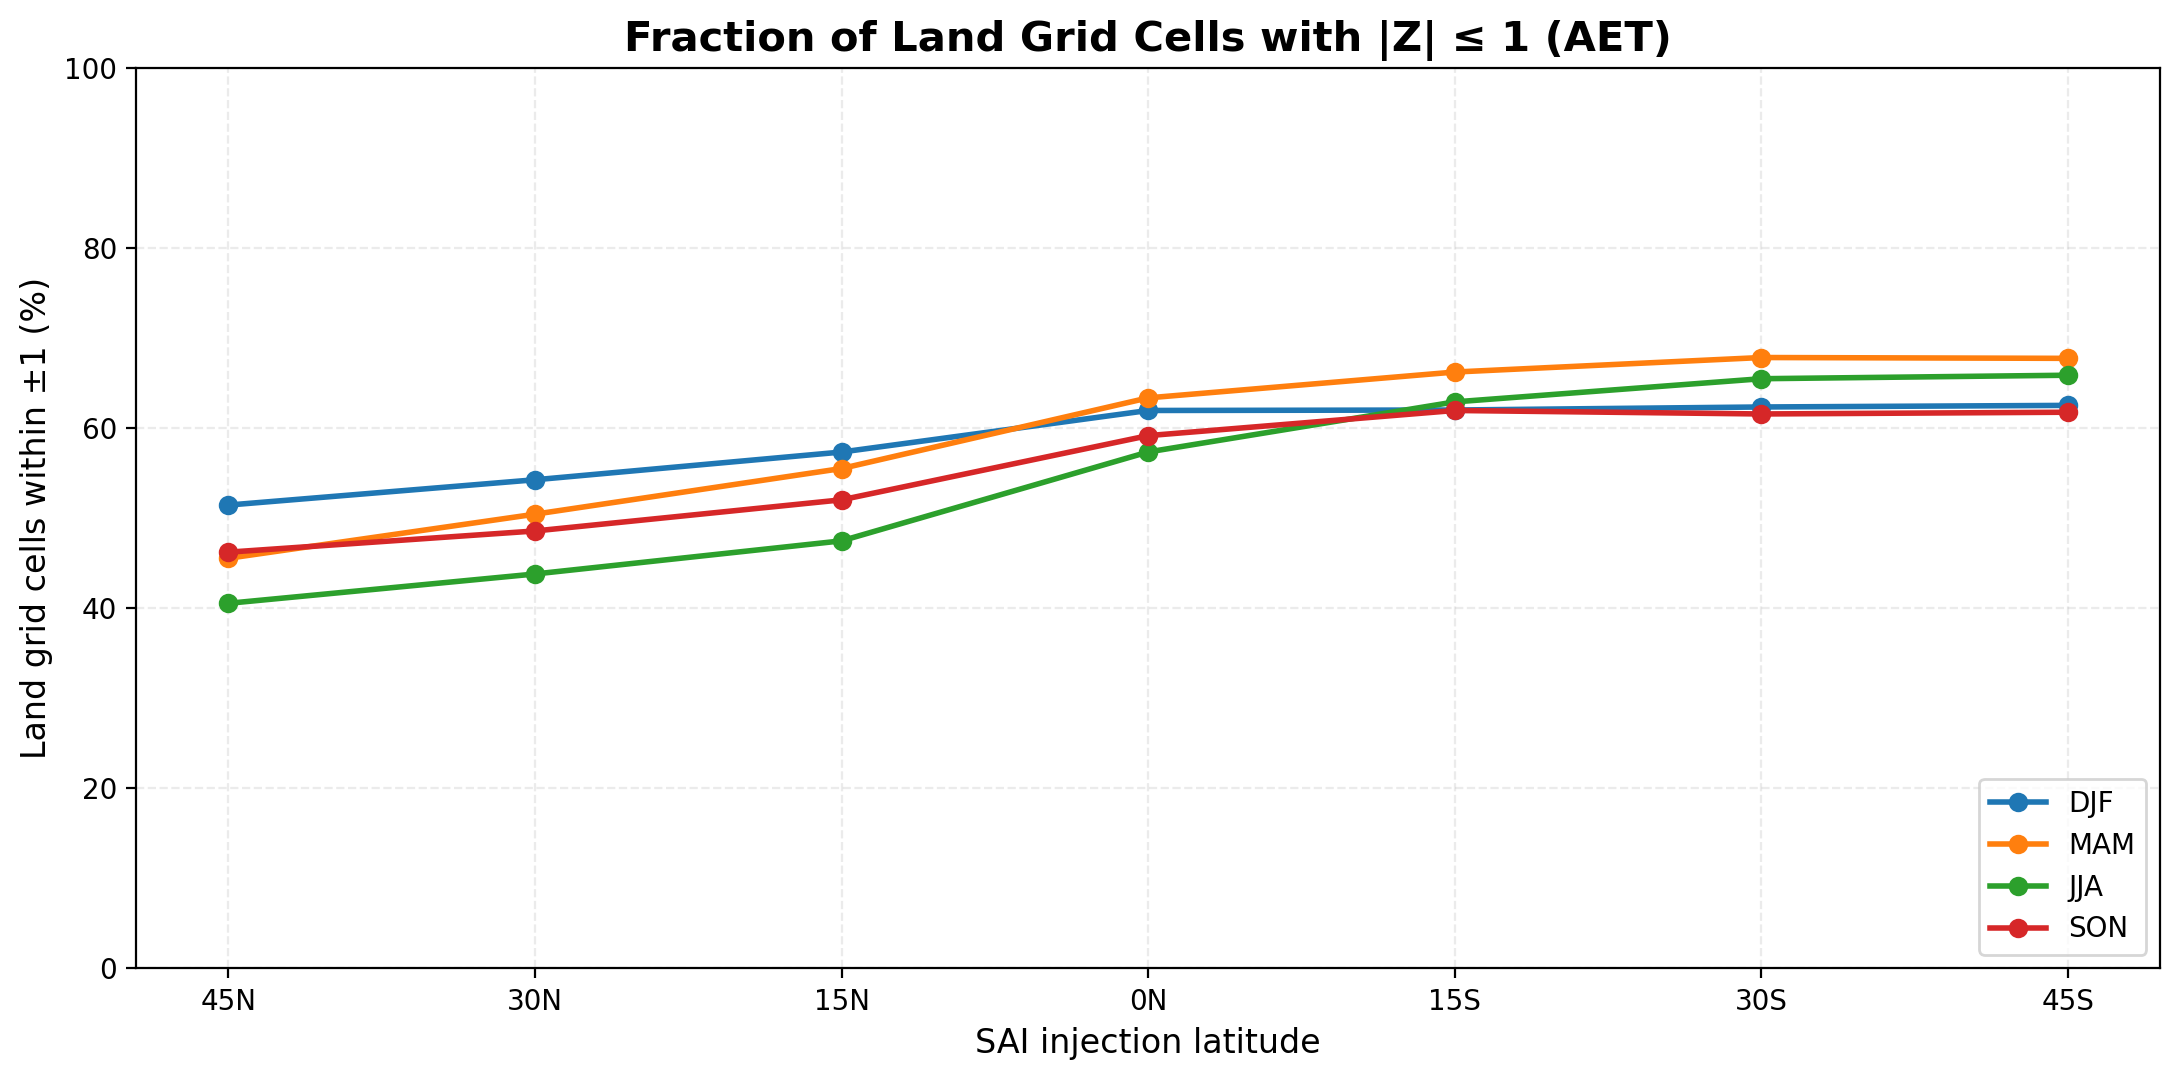

Saved: C:\Users\soyoo\URP_cdo_data\10~11\1118\AET_zscore_validation_within1_pooled.png

AET VALIDATION RESULTS

SAI 45N
  DJF: map |z|<=1:  51.4% | member |z|<=1:  51.3% | map |z|>3:  11.9%
  MAM: map |z|<=1:  45.5% | member |z|<=1:  45.7% | map |z|>3:   7.8%
  JJA: map |z|<=1:  40.5% | member |z|<=1:  40.4% | map |z|>3:  13.6%
  SON: map |z|<=1:  46.2% | member |z|<=1:  46.1% | map |z|>3:  14.3%

SAI 30N
  DJF: map |z|<=1:  54.3% | member |z|<=1:  53.8% | map |z|>3:  11.9%
  MAM: map |z|<=1:  50.4% | member |z|<=1:  50.4% | map |z|>3:   7.1%
  JJA: map |z|<=1:  43.8% | member |z|<=1:  43.7% | map |z|>3:  11.2%
  SON: map |z|<=1:  48.6% | member |z|<=1:  48.4% | map |z|>3:  13.5%

SAI 15N
  DJF: map |z|<=1:  57.3% | member |z|<=1:  57.1% | map |z|>3:  11.9%
  MAM: map |z|<=1:  55.5% | member |z|<=1:  55.3% | map |z|>3:   6.7%
  JJA: map |z|<=1:  47.5% | member |z|<=1:  47.7% | map |z|>3:  10.2%
  SON: map |z|<=1:  52.0% | member |z|<=1:  51.9% | map |z|>3:  12.8%

SAI 0N
  DJF: map |z|

In [1]:
from pathlib import Path

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

# ==========================================
# 1. Settings
# ==========================================

BASE_DIR = Path(
    r"C:\Users\soyoo\URP_cdo_data\10~11\1118"
)

SCENARIOS = [
    "45N", "30N", "15N", "0N",
    "15S", "30S", "45S"
]

SEASONS = ["DJF", "MAM", "JJA", "SON"]

MEMBERS = [
    "e02", "e03", "e04",
    "e05", "e06", "e07"
]

Z_DIRS = {
    "PR": BASE_DIR / "PR_zscore_pooled5",
    "AET": BASE_DIR / "AET_zscore_pooled3"
}

VARIABLE_NAMES = {
    "PR": "pr",
    "AET": "aet"
}

# ==========================================
# 2. Load common spatial mask
# ==========================================

MASK_CANDIDATES = [
    BASE_DIR / "common_spatial_mask.npy",
    BASE_DIR.parent / "1115" / "common_spatial_mask.npy"
]

mask_path = next(
    (p for p in MASK_CANDIDATES if p.is_file()),
    None
)

if mask_path is None:
    raise FileNotFoundError(
        "common_spatial_mask.npy not found "
        "in 1118 or 1115."
    )

valid_mask = np.load(mask_path).astype(bool)

assert valid_mask.shape == (192, 288), (
    f"Unexpected mask shape: {valid_mask.shape}"
)

print("Mask loaded:", mask_path)
print("Mask shape:", valid_mask.shape)
print("Valid grid cells:", valid_mask.sum())

# ==========================================
# 3. Load seasonal z-score
# ==========================================

def read_seasonal_zscore(path, variable):

    if not path.is_file():
        raise FileNotFoundError(path)

    with xr.open_dataset(path) as ds:

        da = ds[variable].transpose(
            "time", "lat", "lon"
        )

        labels = da.time.dt.season.values

        if len(labels) != 4:
            raise ValueError(
                f"Expected 4 seasons: {path}"
            )

        indices = []

        for season in SEASONS:

            matches = np.where(
                labels == season
            )[0]

            if len(matches) != 1:
                raise ValueError(
                    f"Invalid season {season}: {path}"
                )

            indices.append(matches[0])

        values = da.values[indices].copy()

    values[~np.isfinite(values)] = np.nan

    if values.shape != (4, 192, 288):
        raise ValueError(
            f"Unexpected shape: {values.shape}"
        )

    return values


# ==========================================
# 4. Calculate |z| <= 1 fractions
# ==========================================

def calculate_fractions(var):

    z_dir = Z_DIRS[var]
    variable = VARIABLE_NAMES[var]

    within_1 = np.full(
        (len(SEASONS), len(SCENARIOS)),
        np.nan
    )

    outside_3 = np.full_like(
        within_1, np.nan
    )

    member_within_1 = np.full_like(
        within_1, np.nan
    )

    member_counts = {}

    for j, scenario in enumerate(SCENARIOS):

        member_arrays = []
        loaded_members = []

        for member in MEMBERS:

            path = z_dir / (
                f"{var}_zscore_yseasmean_"
                f"{scenario}_{member}.nc"
            )

            if not path.is_file():

                # Known missing AET member
                if var == "AET" and scenario == "15N" and member == "e05":
                    print(f"[KNOWN MISSING] {path.name}")
                else:
                    print(f"[WARNING] Missing: {path.name}")

                continue

            arr = read_seasonal_zscore(
                path, variable
            )

            member_arrays.append(arr)
            loaded_members.append(member)

        if not member_arrays:
            raise ValueError(
                f"No available members for {var} {scenario}"
            )

        stack = np.stack(
            member_arrays,
            axis=0
        )

        member_counts[scenario] = len(
            loaded_members
        )

        print(
            f"\n{var} {scenario}: "
            f"{len(loaded_members)} members "
            f"({', '.join(loaded_members)})"
        )

        # ----------------------------------
        # Ensemble mean of individual z
        # ----------------------------------

        valid_count = np.sum(
            np.isfinite(stack),
            axis=0
        )

        ensemble_mean = np.divide(
            np.nansum(stack, axis=0),
            valid_count,
            out=np.full(
                stack.shape[1:],
                np.nan
            ),
            where=valid_count > 0
        )

        # ----------------------------------
        # Calculate fractions by season
        # ----------------------------------

        for i, season in enumerate(SEASONS):

            # A. Ensemble-mean map
            values = ensemble_mean[i][valid_mask]
            values = values[np.isfinite(values)]

            if values.size > 0:

                within_1[i, j] = (
                    np.mean(np.abs(values) <= 1)
                    * 100
                )

                outside_3[i, j] = (
                    np.mean(np.abs(values) > 3)
                    * 100
                )

            # B. Individual member map values
            member_values = stack[
                :, i, :, :
            ][:, valid_mask]

            member_values = member_values[
                np.isfinite(member_values)
            ]

            if member_values.size > 0:

                member_within_1[i, j] = (
                    np.mean(
                        np.abs(member_values) <= 1
                    ) * 100
                )

    return {
        "within_1": within_1,
        "outside_3": outside_3,
        "member_within_1": member_within_1,
        "member_counts": member_counts
    }


# ==========================================
# 5. Plot validation graph
# ==========================================

def plot_validation(var, results):

    within_1 = results["within_1"]

    fig, ax = plt.subplots(
        figsize=(11, 5.5),
        dpi=200
    )

    for i, season in enumerate(SEASONS):

        ax.plot(
            SCENARIOS,
            within_1[i],
            marker="o",
            linewidth=2,
            markersize=6,
            label=season
        )

    # Professor's expected reference

    ax.set_ylim(0, 100)

    ax.set_xlabel(
        "SAI injection latitude",
        fontsize=12
    )

    ax.set_ylabel(
        "Land grid cells within ±1 (%)",
        fontsize=12
    )

    ax.set_title(
        f"Fraction of Land Grid Cells with "
        f"|Z| ≤ 1 ({var})",
        fontsize=15,
        fontweight="bold"
    )

    ax.grid(
        alpha=0.25,
        linestyle="--"
    )

    ax.legend(
        loc="lower right",
        frameon=True
    )

    plt.tight_layout()

    output_path = BASE_DIR / (
        f"{var}_zscore_validation_within1_pooled.png"
    )

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", output_path)


# ==========================================
# 6. Print diagnostics
# ==========================================

def print_diagnostics(var, results):

    within_1 = results["within_1"]
    outside_3 = results["outside_3"]
    member_within_1 = results["member_within_1"]

    print("\n" + "=" * 60)
    print(f"{var} VALIDATION RESULTS")
    print("=" * 60)

    for j, scenario in enumerate(SCENARIOS):

        print(f"\nSAI {scenario}")

        for i, season in enumerate(SEASONS):

            print(
                f"  {season}: "
                f"map |z|<=1: "
                f"{within_1[i,j]:5.1f}% | "
                f"member |z|<=1: "
                f"{member_within_1[i,j]:5.1f}% | "
                f"map |z|>3: "
                f"{outside_3[i,j]:5.1f}%"
            )

    print("\nOverall average:")

    print(
        "Map |z| <= 1:",
        f"{np.nanmean(within_1):.1f}%"
    )

    print(
        "Member |z| <= 1:",
        f"{np.nanmean(member_within_1):.1f}%"
    )

    print(
        "Map |z| > 3:",
        f"{np.nanmean(outside_3):.1f}%"
    )


# ==========================================
# 7. Run PR and AET
# ==========================================

pr_results = calculate_fractions("PR")

plot_validation(
    "PR",
    pr_results
)

print_diagnostics(
    "PR",
    pr_results
)


aet_results = calculate_fractions("AET")

plot_validation(
    "AET",
    aet_results
)

print_diagnostics(
    "AET",
    aet_results
)

print("\nAll validation graphs completed.")